In [ ]:
import os
import re
import pandas as pd
from sklearn.metrics import pairwise_distances
from sklearn.metrics import f1_score
from collections import Counter
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/output/metafeatures/all_metafeatures.csv", sep=";")
df["task"] = df["dataset_name"].apply(lambda x: x[:2])
df = df.drop(columns=["total_number_instances", "number_instances_train"], axis=1)
df

,number_labels,class_imbalance,entropy_vocabulary_distribution,entropy_words_per_document,vocabulary,vocabulary_document_ratio,ratio_mean_std_dev_tokens,ratio_mean_std_dev_unique_tokens,pca_noise_variance,minimum_number_tokens_per_document,...,kurtosis_pca_explained_variance,minimum_pca_explained_variance_ratio,maximum_pca_explained_variance_ratio,average_pca_explained_variance_ratio,standard_deviation_pca_explained_variance_ratio,skewness_pca_explained_variance_ratio,kurtosis_pca_explained_variance_ratio,dataset_name,duration,task
0,5.0,6.393542,9.335635,9.259538,14343.0,167.428571,1.022916,1.262385,0.0,8.0,...,29.996689,3.446450e-10,0.991561,0.033333,0.180985,5.476789,29.996689,ua_06,0 days 00:07:17.542934,ua
1,5.0,23.833333,6.546110,6.392680,937.0,299.000000,0.850790,1.155693,0.0,1.0,...,29.999628,0.000000e+00,0.995094,0.033333,0.181648,5.477176,29.999628,ua_05,0 days 00:00:23.946449,ua
2,5.0,1.003568,11.949349,11.848534,199422.0,213.000000,1.008527,1.280241,0.0,2.0,...,29.995935,1.966153e-07,0.988957,0.033333,0.180494,5.476690,29.995935,ua_04,0 days 00:42:06.104410,ua
3,5.0,35.115108,8.595951,8.413563,7176.0,415.500000,0.787439,1.125014,0.0,2.0,...,29.999956,8.625121e-18,0.998282,0.033333,0.182250,5.477220,29.999956,ua_03,0 days 00:02:57.267165,ua
4,10.0,7.158416,7.762931,7.649876,3030.0,355.000000,0.998308,1.304117,0.0,1.0,...,29.997796,0.000000e+00,0.991533,0.033333,0.180978,5.476935,29.997796,ua_02,0 days 00:00:57.670232,ua
5,5.0,9.875441,11.471933,11.386489,141202.0,224.000000,0.861291,1.002520,0.0,1.0,...,29.214681,1.785258e-06,0.890903,0.033333,0.162939,5.380087,29.214681,ua_01,0 days 00:18:55.527703,ua
6,3.0,1.427984,6.657086,6.629168,875.0,68.000000,1.884158,2.104591,0.0,1.0,...,28.971355,1.592367e-06,0.872084,0.033333,0.159665,5.351107,28.971355,sd_04,0 days 00:00:14.975728,sd
7,3.0,1.240602,6.672803,6.647840,875.0,32.000000,2.028728,2.276415,0.0,2.0,...,28.447378,1.347655e-06,0.849677,0.033333,0.156042,5.289911,28.447378,sd_03,0 days 00:00:15.942621,sd
8,5.0,4.070286,12.651070,12.502195,398237.0,7876.000000,0.881511,1.269785,0.0,1.0,...,29.999973,6.889622e-11,0.998740,0.033333,0.182336,5.477222,29.999973,sd_02,0 days 17:44:10.919396,sd
9,2.0,1.551136,5.896811,5.749905,449.0,71.142857,0.991453,1.435320,0.0,23.0,...,29.999973,3.238468e-10,0.998714,0.033333,0.182331,5.477222,29.999973,sd_01,0 days 00:01:14.359312,sd


In [ ]:
ed_df = df[df["task"]=="ed"]
ed_df = ed_df.drop(columns=["task","duration"])
fn_df = df[df["task"]=="fn"]
fn_df = fn_df.drop(columns=["task","duration"])
hs_df = df[df["task"]=="hs"]
hs_df = hs_df.drop(columns=["task","duration"])
pc_df = df[df["task"]=="pc"]
pc_df = pc_df.drop(columns=["task","duration"])
sd_df = df[df["task"]=="sd"]
sd_df = sd_df.drop(columns=["task","duration"])
ua_df = df[df["task"]=="ua"]
ua_df = ua_df.drop(columns=["task","duration"])

In [ ]:
ua_df

,number_labels,class_imbalance,entropy_vocabulary_distribution,entropy_words_per_document,vocabulary,vocabulary_document_ratio,ratio_mean_std_dev_tokens,ratio_mean_std_dev_unique_tokens,pca_noise_variance,minimum_number_tokens_per_document,...,standard_deviation_pca_explained_variance,skewness_pca_explained_variance,kurtosis_pca_explained_variance,minimum_pca_explained_variance_ratio,maximum_pca_explained_variance_ratio,average_pca_explained_variance_ratio,standard_deviation_pca_explained_variance_ratio,skewness_pca_explained_variance_ratio,kurtosis_pca_explained_variance_ratio,dataset_name
0,5.0,6.393542,9.335635,9.259538,14343.0,167.428571,1.022916,1.262385,0.0,8.0,...,81407.775084,5.476789,29.996689,3.446450e-10,0.991561,0.033333,0.180985,5.476789,29.996689,ua_06
1,5.0,23.833333,6.546110,6.392680,937.0,299.000000,0.850790,1.155693,0.0,1.0,...,21320.244850,5.477176,29.999628,0.000000e+00,0.995094,0.033333,0.181648,5.477176,29.999628,ua_05
2,5.0,1.003568,11.949349,11.848534,199422.0,213.000000,1.008527,1.280241,0.0,2.0,...,6316.475420,5.476690,29.995935,1.966153e-07,0.988957,0.033333,0.180494,5.476690,29.995935,ua_04
3,5.0,35.115108,8.595951,8.413563,7176.0,415.500000,0.787439,1.125014,0.0,2.0,...,74495.043856,5.477220,29.999956,8.625121e-18,0.998282,0.033333,0.182250,5.477220,29.999956,ua_03
4,10.0,7.158416,7.762931,7.649876,3030.0,355.000000,0.998308,1.304117,0.0,1.0,...,14789.126423,5.476935,29.997796,0.000000e+00,0.991533,0.033333,0.180978,5.476935,29.997796,ua_02
5,5.0,9.875441,11.471933,11.386489,141202.0,224.000000,0.861291,1.002520,0.0,1.0,...,1971.340360,5.380087,29.214681,1.785258e-06,0.890903,0.033333,0.162939,5.380087,29.214681,ua_01


## ed

In [ ]:
ed_numeric_df = ed_df.drop(columns=["dataset_name"])
ed_numeric_df = ed_numeric_df.dropna()
ed_distance_matrix = pairwise_distances(ed_numeric_df, metric='euclidean')
ed_distance_matrix_df = pd.DataFrame(ed_distance_matrix, index=ed_df["dataset_name"], columns=ed_df["dataset_name"])

display(ed_distance_matrix)
display(ed_numeric_df)

array([[     0.        ,  22599.02289435,  51730.45013894,
        272481.48491764,   1454.48625543],
       [ 22599.02289435,      0.        ,  37052.62143917,
        251593.44690917,  21814.84033155],
       [ 51730.45013894,  37052.62143917,      0.        ,
        231636.96503445,  51354.04189529],
       [272481.48491764, 251593.44690917, 231636.96503445,
             0.        , 272038.87745389],
       [  1454.48625543,  21814.84033155,  51354.04189529,
        272038.87745389,      0.        ]])

,number_labels,class_imbalance,entropy_vocabulary_distribution,entropy_words_per_document,vocabulary,vocabulary_document_ratio,ratio_mean_std_dev_tokens,ratio_mean_std_dev_unique_tokens,pca_noise_variance,minimum_number_tokens_per_document,...,average_pca_explained_variance,standard_deviation_pca_explained_variance,skewness_pca_explained_variance,kurtosis_pca_explained_variance,minimum_pca_explained_variance_ratio,maximum_pca_explained_variance_ratio,average_pca_explained_variance_ratio,standard_deviation_pca_explained_variance_ratio,skewness_pca_explained_variance_ratio,kurtosis_pca_explained_variance_ratio
44,5.0,6.171429,6.278830,6.274701,555.0,37.000000,3.544061,3.723471,0.0,1.0,...,38.073176,140.256066,4.045057,16.348752,3.282735e-06,0.588929,0.033333,0.122795,4.045057,16.348752
45,3.0,1154.352941,9.730786,9.659400,21495.0,141.000000,1.053699,1.267930,0.0,1.0,...,303.785836,1545.487363,5.441756,29.720765,3.063061e-07,0.929316,0.033333,0.169581,5.441756,29.720765
46,28.0,228.196429,10.556112,10.538489,43195.0,58.000000,1.714360,2.118875,0.0,1.0,...,70.493513,290.205592,4.811027,24.057929,4.964155e-06,0.723831,0.033333,0.137226,4.811027,24.057929
47,6.0,10.808854,12.389487,12.363662,272862.0,93.000000,1.759815,1.958202,0.0,1.0,...,128.462267,653.517673,5.440614,29.711563,0.000000e+00,0.929220,0.033333,0.169574,5.440614,29.711563
48,6.0,13.807692,6.853063,6.850457,986.0,6.333333,3.349898,3.470208,0.0,3.0,...,67.236632,334.285309,5.441281,29.718448,0.000000e+00,0.908932,0.033333,0.165726,5.441281,29.718448


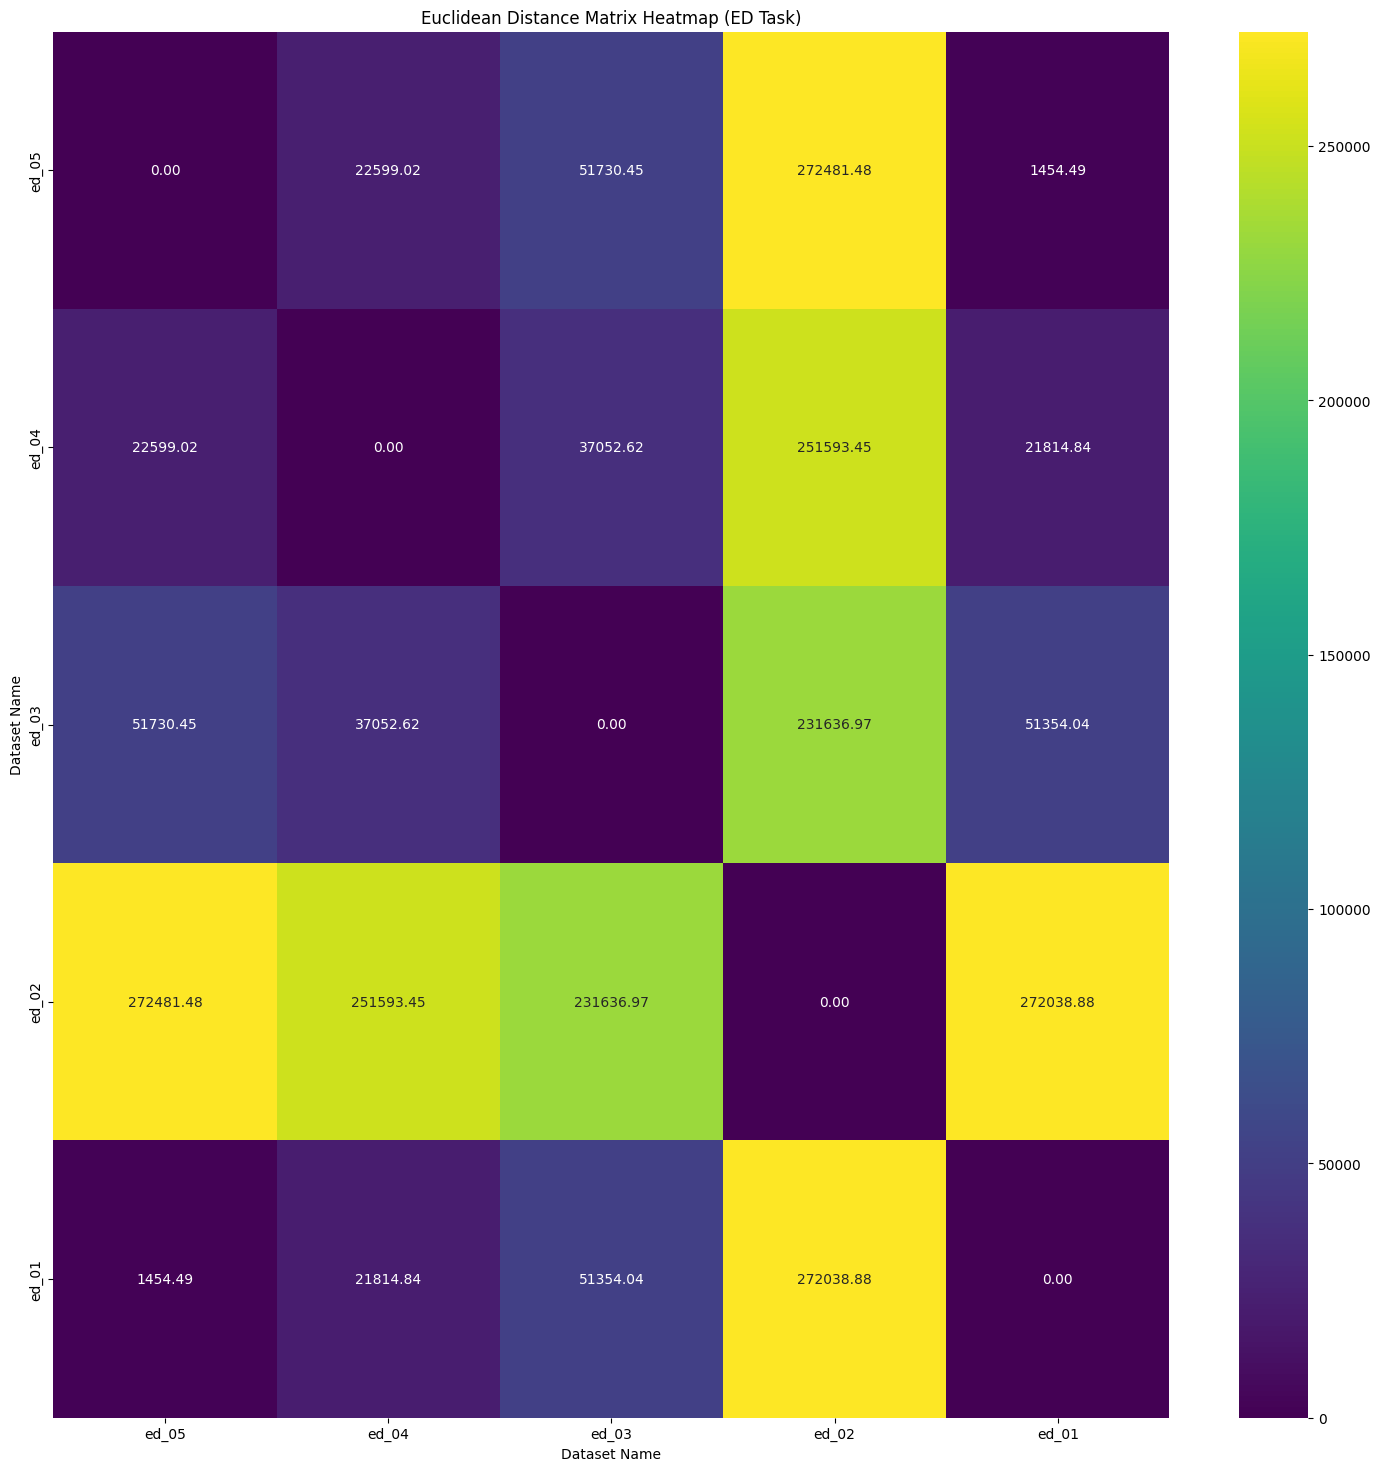

In [ ]:
plt.figure(figsize=(18, 18))
sns.heatmap(ed_distance_matrix_df, annot=True, fmt=".2f", cmap="viridis")
plt.title("Euclidean Distance Matrix Heatmap (ED Task)")
plt.xlabel("Dataset Name")
plt.ylabel("Dataset Name")
plt.show()

## fn

array([[0.00000000e+00, 1.55032277e+03, 4.15102630e+03, 6.71520912e+02,
        1.55304672e+06, 1.39024397e+05, 4.49626230e+03, 7.60917994e+03,
        3.98842734e+04, 9.62669305e+03],
       [1.55032277e+03, 0.00000000e+00, 3.85938985e+03, 1.61543138e+03,
        1.55281686e+06, 1.37548372e+05, 3.82999294e+03, 6.09201761e+03,
        3.97017792e+04, 8.09529505e+03],
       [4.15102630e+03, 3.85938985e+03, 0.00000000e+00, 3.63238671e+03,
        1.54905708e+06, 1.38152293e+05, 5.16911437e+03, 6.78402106e+03,
        3.59246182e+04, 8.82537920e+03],
       [6.71520912e+02, 1.61543138e+03, 3.63238671e+03, 0.00000000e+00,
        1.55253791e+06, 1.39041726e+05, 4.53990076e+03, 7.49267975e+03,
        3.93771092e+04, 9.54240643e+03],
       [1.55304672e+06, 1.55281686e+06, 1.54905708e+06, 1.55253791e+06,
        0.00000000e+00, 1.55918261e+06, 1.55231780e+06, 1.55130417e+06,
        1.51316740e+06, 1.55144848e+06],
       [1.39024397e+05, 1.37548372e+05, 1.38152293e+05, 1.39041726e+05,
   

,number_labels,class_imbalance,entropy_vocabulary_distribution,entropy_words_per_document,vocabulary,vocabulary_document_ratio,ratio_mean_std_dev_tokens,ratio_mean_std_dev_unique_tokens,pca_noise_variance,minimum_number_tokens_per_document,...,average_pca_explained_variance,standard_deviation_pca_explained_variance,skewness_pca_explained_variance,kurtosis_pca_explained_variance,minimum_pca_explained_variance_ratio,maximum_pca_explained_variance_ratio,average_pca_explained_variance_ratio,standard_deviation_pca_explained_variance_ratio,skewness_pca_explained_variance_ratio,kurtosis_pca_explained_variance_ratio
34,4.0,4.730337,6.685734,6.684940,833.0,13.000000,3.689542,3.739654,0.0,3.0,...,38.988783,139.303396,3.714892,12.841252,5.899546e-06,0.513993,0.033333,0.119097,3.714892,12.841252
35,4.0,2.800000,7.715669,7.712375,2357.0,39.000000,3.230487,3.329535,0.0,1.0,...,46.599533,173.175558,4.042016,16.314986,6.374720e-06,0.593417,0.033333,0.123875,4.042016,16.314986
36,5.0,115.769231,7.370863,7.346544,1767.0,12.833333,1.838578,2.078065,0.0,6.0,...,165.162539,826.877419,5.425659,29.590658,1.901907e-17,0.914184,0.033333,0.166882,5.425659,29.590658
37,3.0,1.099617,6.656644,6.644222,819.0,14.333333,2.718773,3.065162,0.0,3.0,...,48.855473,207.920549,4.923036,25.118829,1.045395e-19,0.754503,0.033333,0.141861,4.923036,25.118829
38,2.0,1.114943,6.187789,6.139228,552.0,31.285714,1.601925,1.919781,0.0,23.0,...,50975.105620,278885.696621,5.477223,29.999983,1.193778e-17,0.998904,0.033333,0.182367,5.477223,29.999983
39,3.0,2.619878,11.768540,11.762566,135507.0,23.333333,2.919043,3.136955,0.0,3.0,...,35.050895,137.713345,4.465627,20.671997,0.000000e+00,0.667880,0.033333,0.130965,4.465627,20.671997
40,12.0,257.000000,8.133620,8.125924,3560.0,13.400000,3.004311,3.297562,0.0,5.0,...,56.787187,247.570060,5.054270,26.340465,1.637059e-07,0.780321,0.033333,0.145320,5.054270,26.340465
41,9.0,115.785714,8.937307,8.917415,8147.0,34.500000,2.316162,2.681425,0.0,2.0,...,93.805287,430.471524,5.237796,27.992546,3.759881e-17,0.830667,0.033333,0.152966,5.237796,27.992546
42,2.0,1.036364,5.789494,5.778492,336.0,3.545455,3.458250,4.131472,0.0,65.0,...,1351.199362,7265.253444,5.476395,29.993692,0.000000e+00,0.982247,0.033333,0.179230,5.476395,29.993692
43,6.0,2.518430,9.167826,9.148729,10251.0,33.500000,2.344488,2.701427,0.0,2.0,...,89.463785,407.151563,5.208087,27.730051,1.176753e-17,0.822376,0.033333,0.151701,5.208087,27.730051


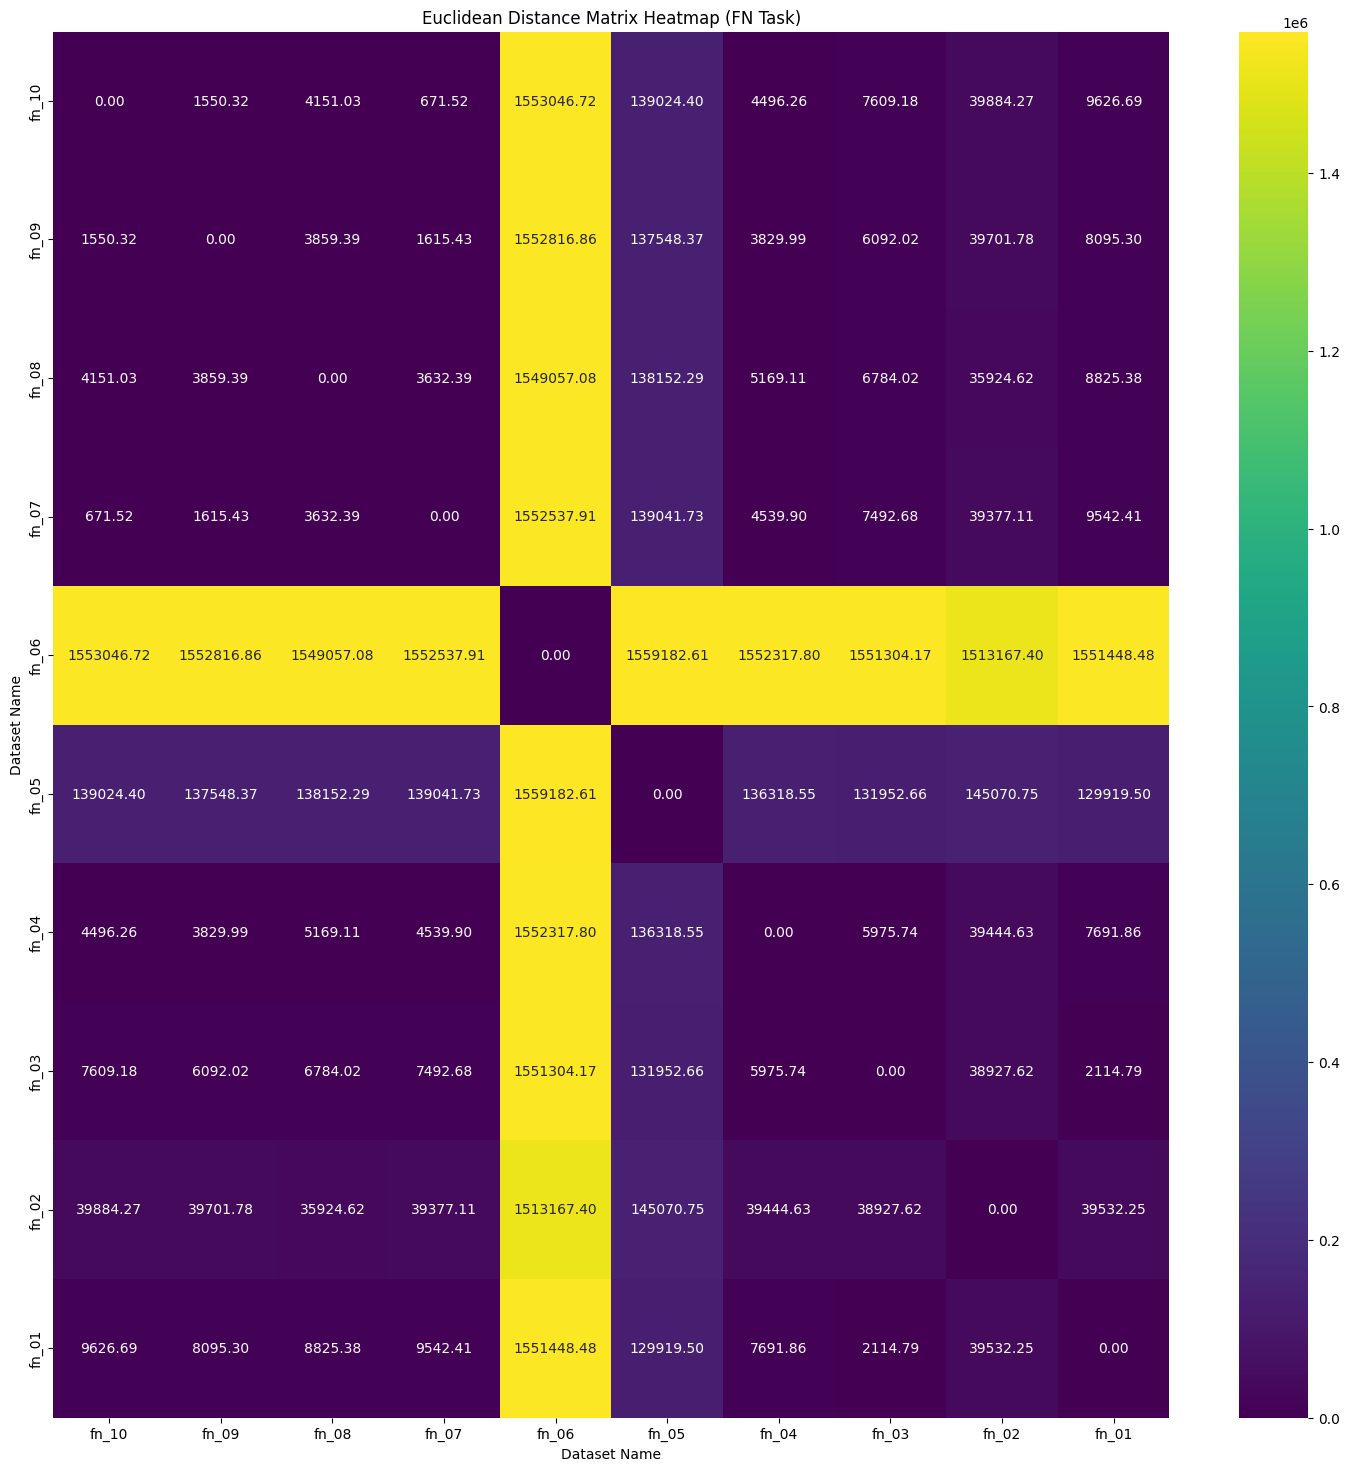

In [ ]:
fn_numeric_df = fn_df.drop(columns=["dataset_name"])
fn_numeric_df = fn_numeric_df.dropna()
fn_distance_matrix = pairwise_distances(fn_numeric_df, metric='euclidean')
fn_distance_matrix_df = pd.DataFrame(fn_distance_matrix, index=fn_df["dataset_name"], columns=fn_df["dataset_name"])

display(fn_distance_matrix)
display(fn_numeric_df)

plt.figure(figsize=(18, 18))
sns.heatmap(fn_distance_matrix_df, annot=True, fmt=".2f", cmap="viridis")
plt.title("Euclidean Distance Matrix Heatmap (FN Task)")
plt.xlabel("Dataset Name")
plt.ylabel("Dataset Name")
plt.show()

## hs

array([[0.00000000e+00, 2.32531908e+04, 3.37578608e+04, 3.40244928e+04,
        3.41438425e+04, 3.34787534e+04, 3.33381487e+04, 2.64291918e+04,
        2.48433513e+04, 2.76562909e+04, 2.53654610e+04, 3.69989743e+05,
        3.13405260e+04, 2.73185065e+04, 3.19492672e+04],
       [2.32531908e+04, 0.00000000e+00, 2.11041911e+04, 2.11612164e+04,
        2.13644962e+04, 2.43597491e+04, 2.09162477e+04, 1.92534734e+04,
        1.31397806e+04, 1.52857346e+04, 1.95855359e+04, 3.80826028e+05,
        1.73276561e+04, 1.83880940e+04, 1.98938773e+04],
       [3.37578608e+04, 2.11041911e+04, 0.00000000e+00, 1.57017234e+03,
        8.46717597e+02, 3.54993630e+04, 1.16603878e+03, 1.88985564e+04,
        1.29744853e+04, 8.32155128e+03, 1.28355287e+04, 3.98913908e+05,
        4.68150570e+03, 1.56632294e+04, 2.35746083e+03],
       [3.40244928e+04, 2.11612164e+04, 1.57017234e+03, 0.00000000e+00,
        1.08104511e+03, 3.45610150e+04, 2.67706331e+03, 2.01444633e+04,
        1.37515865e+04, 9.13518589e+0

,number_labels,class_imbalance,entropy_vocabulary_distribution,entropy_words_per_document,vocabulary,vocabulary_document_ratio,ratio_mean_std_dev_tokens,ratio_mean_std_dev_unique_tokens,pca_noise_variance,minimum_number_tokens_per_document,...,average_pca_explained_variance,standard_deviation_pca_explained_variance,skewness_pca_explained_variance,kurtosis_pca_explained_variance,minimum_pca_explained_variance_ratio,maximum_pca_explained_variance_ratio,average_pca_explained_variance_ratio,standard_deviation_pca_explained_variance_ratio,skewness_pca_explained_variance_ratio,kurtosis_pca_explained_variance_ratio
19,5.0,295.454545,9.823026,9.766811,21744.0,140.000000,1.399743,1.675914,0.0,1.0,...,668.915994,3532.211493,5.469919,29.943785,8.567909e-08,0.964886,0.033333,0.176017,5.469919,29.943785
20,2.0,4.110350,9.176421,9.050626,12687.0,234.000000,0.789846,1.188978,0.0,1.0,...,645.252797,3089.141267,5.334144,28.827060,2.570137e-17,0.870711,0.033333,0.159583,5.334144,28.827060
21,3.0,11.979798,7.256410,7.249646,1534.0,12.666667,2.508800,2.605652,0.0,3.0,...,56.292148,236.005190,4.901479,24.916741,1.524918e-06,0.742422,0.033333,0.139750,4.901479,24.916741
22,2.0,1.027972,5.513453,5.517939,285.0,37.000000,1.913176,1.898209,0.0,1.0,...,107.174502,420.619767,4.549220,21.517764,1.110378e-05,0.673783,0.033333,0.130821,4.549220,21.517764
23,2.0,1.164384,6.570619,6.544565,790.0,15.666667,1.895114,2.168437,0.0,3.0,...,61.707981,260.359355,4.859782,24.518417,0.000000e+00,0.744217,0.033333,0.140641,4.859782,24.518417
24,2.0,1.338926,6.232606,5.992919,697.0,134.333333,0.482714,0.928467,0.0,3.0,...,1238.742171,6587.211274,5.473723,29.973257,3.270746e-10,0.971650,0.033333,0.177255,5.473723,29.973257
25,2.0,24.663366,7.809520,7.805885,2590.0,15.000000,3.142144,3.291458,0.0,3.0,...,49.117284,180.174547,3.994111,15.824375,1.353119e-05,0.580462,0.033333,0.122275,3.994111,15.824375
26,2.0,14.187174,9.845033,9.800526,20365.0,53.000000,1.919620,2.647612,0.0,1.0,...,91.831603,333.149960,3.993185,15.874223,4.336925e-06,0.575405,0.033333,0.120928,3.993185,15.874223
27,2.0,2.004106,9.277246,9.242322,13152.0,84.000000,1.418693,1.549018,0.0,1.0,...,255.637587,1254.295994,5.394425,29.334059,1.920659e-06,0.894915,0.033333,0.163551,5.394425,29.334059
28,2.0,1.375827,8.982518,8.957663,8980.0,80.000000,1.822876,2.025285,0.0,1.0,...,196.835702,888.565342,5.179884,27.479271,5.944260e-07,0.814380,0.033333,0.150475,5.179884,27.479271


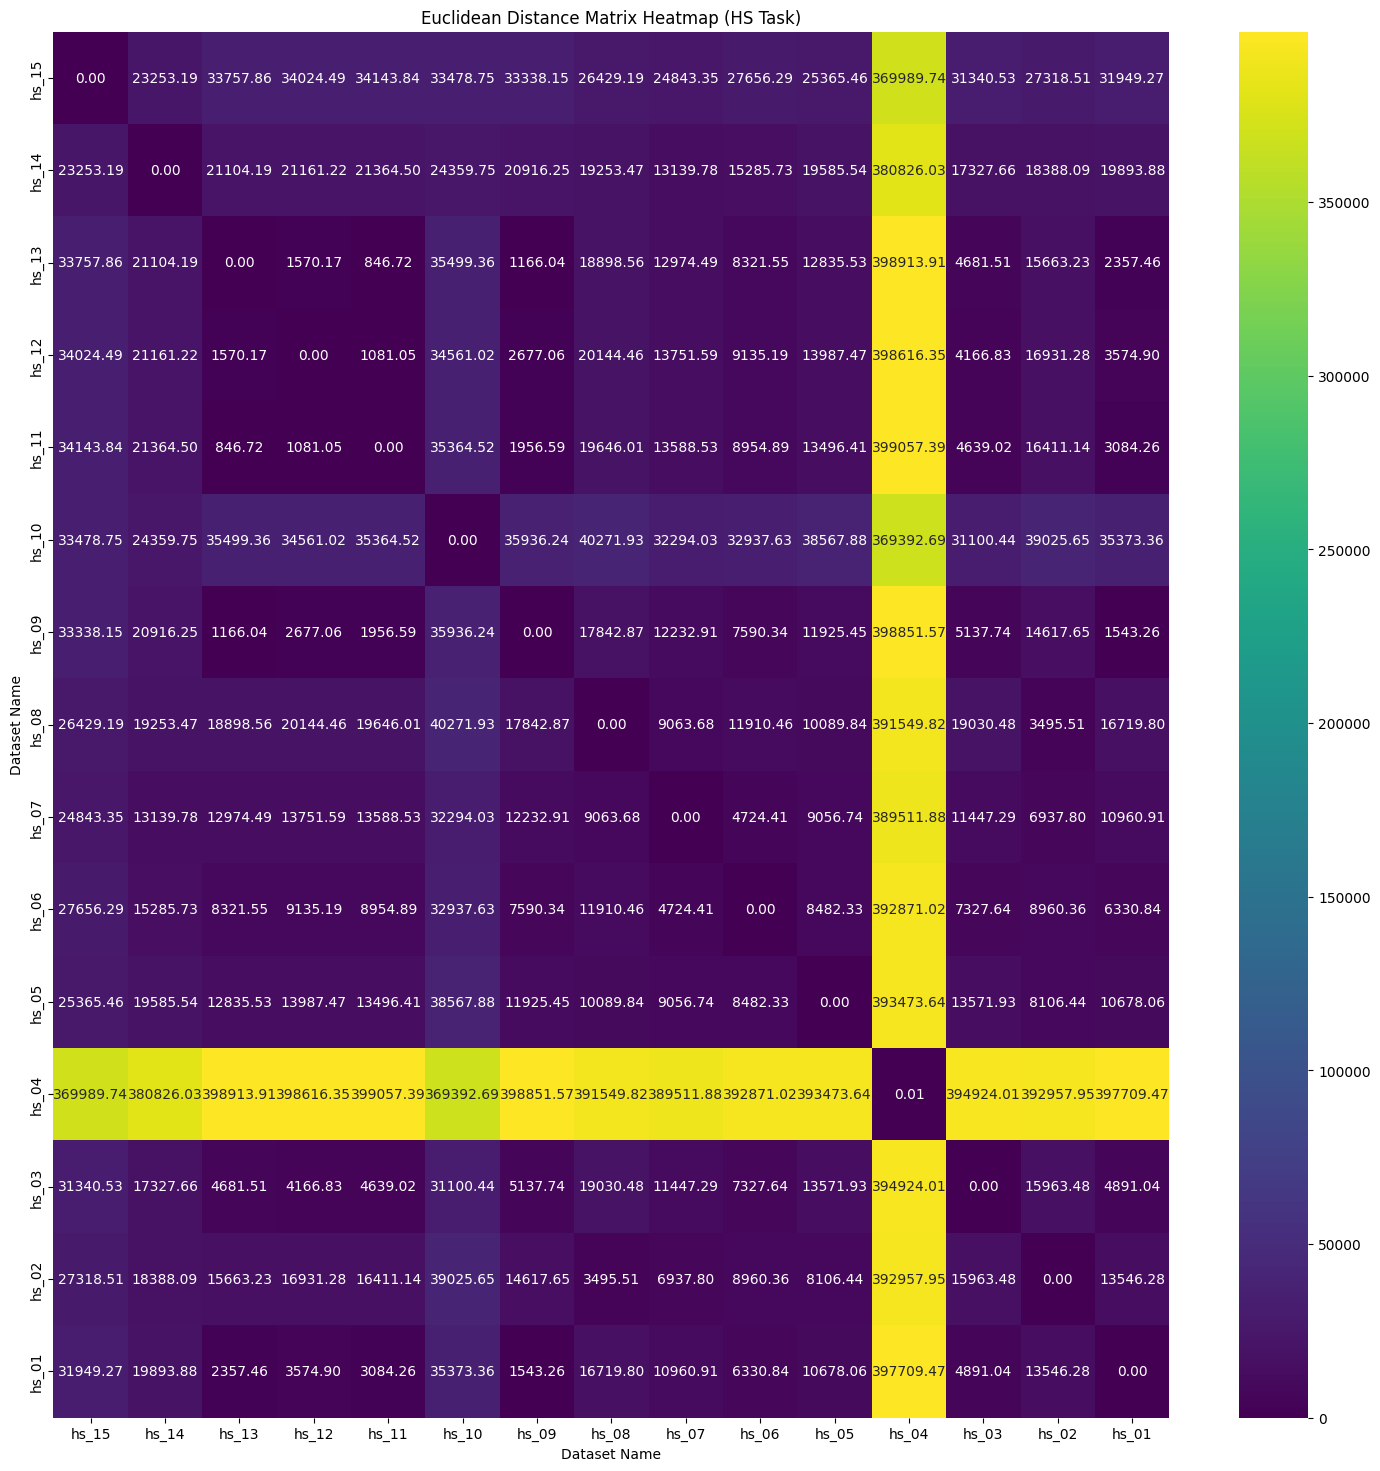

In [ ]:
hs_numeric_df = hs_df.drop(columns=["dataset_name"])
hs_numeric_df = hs_numeric_df.dropna()
hs_distance_matrix = pairwise_distances(hs_numeric_df, metric='euclidean')
hs_distance_matrix_df = pd.DataFrame(hs_distance_matrix, index=hs_df["dataset_name"], columns=hs_df["dataset_name"])

display(hs_distance_matrix)
display(hs_numeric_df)

plt.figure(figsize=(18, 18))
sns.heatmap(hs_distance_matrix_df, annot=True, fmt=".2f", cmap="viridis")
plt.title("Euclidean Distance Matrix Heatmap (HS Task)")
plt.xlabel("Dataset Name")
plt.ylabel("Dataset Name")
plt.show()

## pc

array([[0.00000000e+00, 5.25967322e+06, 7.49789938e+02, 9.35252515e+05,
        1.09585307e+04, 3.60746540e+06, 1.02092702e+06, 1.52464603e+06,
        7.97426932e+03],
       [5.25967322e+06, 0.00000000e+00, 5.25897468e+06, 4.87342507e+06,
        5.25940654e+06, 6.32816022e+06, 4.23912586e+06, 5.47456090e+06,
        5.25726746e+06],
       [7.49789938e+02, 5.25897468e+06, 0.00000000e+00, 9.34776841e+05,
        1.07328799e+04, 3.60722051e+06, 1.02022327e+06, 1.52441083e+06,
        7.56524878e+03],
       [9.35252515e+05, 4.87342507e+06, 9.34776841e+05, 0.00000000e+00,
        9.28666961e+05, 3.13796219e+06, 9.80449446e+05, 1.22588817e+06,
        9.29575113e+05],
       [1.09585307e+04, 5.25940654e+06, 1.07328799e+04, 9.28666961e+05,
        0.00000000e+00, 3.59658102e+06, 1.02045544e+06, 1.51371168e+06,
        4.00655215e+03],
       [3.60746540e+06, 6.32816022e+06, 3.60722051e+06, 3.13796219e+06,
        3.59658102e+06, 0.00000000e+00, 3.70923907e+06, 2.09132108e+06,
        3.5

,number_labels,class_imbalance,entropy_vocabulary_distribution,entropy_words_per_document,vocabulary,vocabulary_document_ratio,ratio_mean_std_dev_tokens,ratio_mean_std_dev_unique_tokens,pca_noise_variance,minimum_number_tokens_per_document,...,average_pca_explained_variance,standard_deviation_pca_explained_variance,skewness_pca_explained_variance,kurtosis_pca_explained_variance,minimum_pca_explained_variance_ratio,maximum_pca_explained_variance_ratio,average_pca_explained_variance_ratio,standard_deviation_pca_explained_variance_ratio,skewness_pca_explained_variance_ratio,kurtosis_pca_explained_variance_ratio
10,4.0,11.183673,6.742706,6.735633,884.0,10.500000,3.124801,3.416018,0.0,2.0,...,19.966327,78.314157,4.694583,22.966403,0.000000e+00,0.683916,0.033333,0.130744,4.694583,22.966403
11,3.0,5.002849,7.945673,7.805413,3350.0,657.500000,0.835485,1.376822,0.0,4.0,...,172593.925875,944192.201079,5.477222,29.999975,2.233272e-10,0.998830,0.033333,0.182353,5.477222,29.999975
12,3.0,5.213592,6.949803,6.943342,1119.0,20.000000,2.617435,2.748890,0.0,2.0,...,52.767147,210.889114,4.632083,22.319039,0.000000e+00,0.691512,0.033333,0.133220,4.632083,22.319039
13,2.0,1.002912,13.007506,12.894107,556401.0,662.000000,1.090570,1.419167,0.0,1.0,...,14975.360040,81733.867059,5.477189,29.999727,2.471716e-18,0.996586,0.033333,0.181930,5.477189,29.999727
14,3.0,3.559060,9.346443,9.340860,11821.0,50.000000,3.766457,4.101190,0.0,1.0,...,33.940688,130.786107,4.587664,21.899363,3.231119e-17,0.664955,0.033333,0.128446,4.587664,21.899363
15,2.0,1.002034,14.987697,14.947983,3589561.0,233.000000,1.839218,2.169434,0.0,1.0,...,1946.056178,10554.867235,5.476972,29.998081,1.813239e-10,0.990543,0.033333,0.180791,5.476972,29.998081
16,2.0,1.003298,9.974251,9.899740,24903.0,74.272727,1.337121,1.700552,0.0,11.0,...,33514.352076,183272.704663,5.477222,29.999975,1.196405e-10,0.998457,0.033333,0.182283,5.477222,29.999975
17,2.0,1.018004,14.125376,14.108571,1525157.0,60.000000,1.955257,2.141915,0.0,1.0,...,61.528959,258.413894,4.916467,25.058618,4.067134e-08,0.744621,0.033333,0.139996,4.916467,25.058618
18,2.0,1.003545,8.956295,8.944649,8477.0,28.500000,2.265786,2.420837,0.0,2.0,...,117.378688,517.073347,5.053087,26.328168,2.693382e-17,0.788045,0.033333,0.146839,5.053087,26.328168


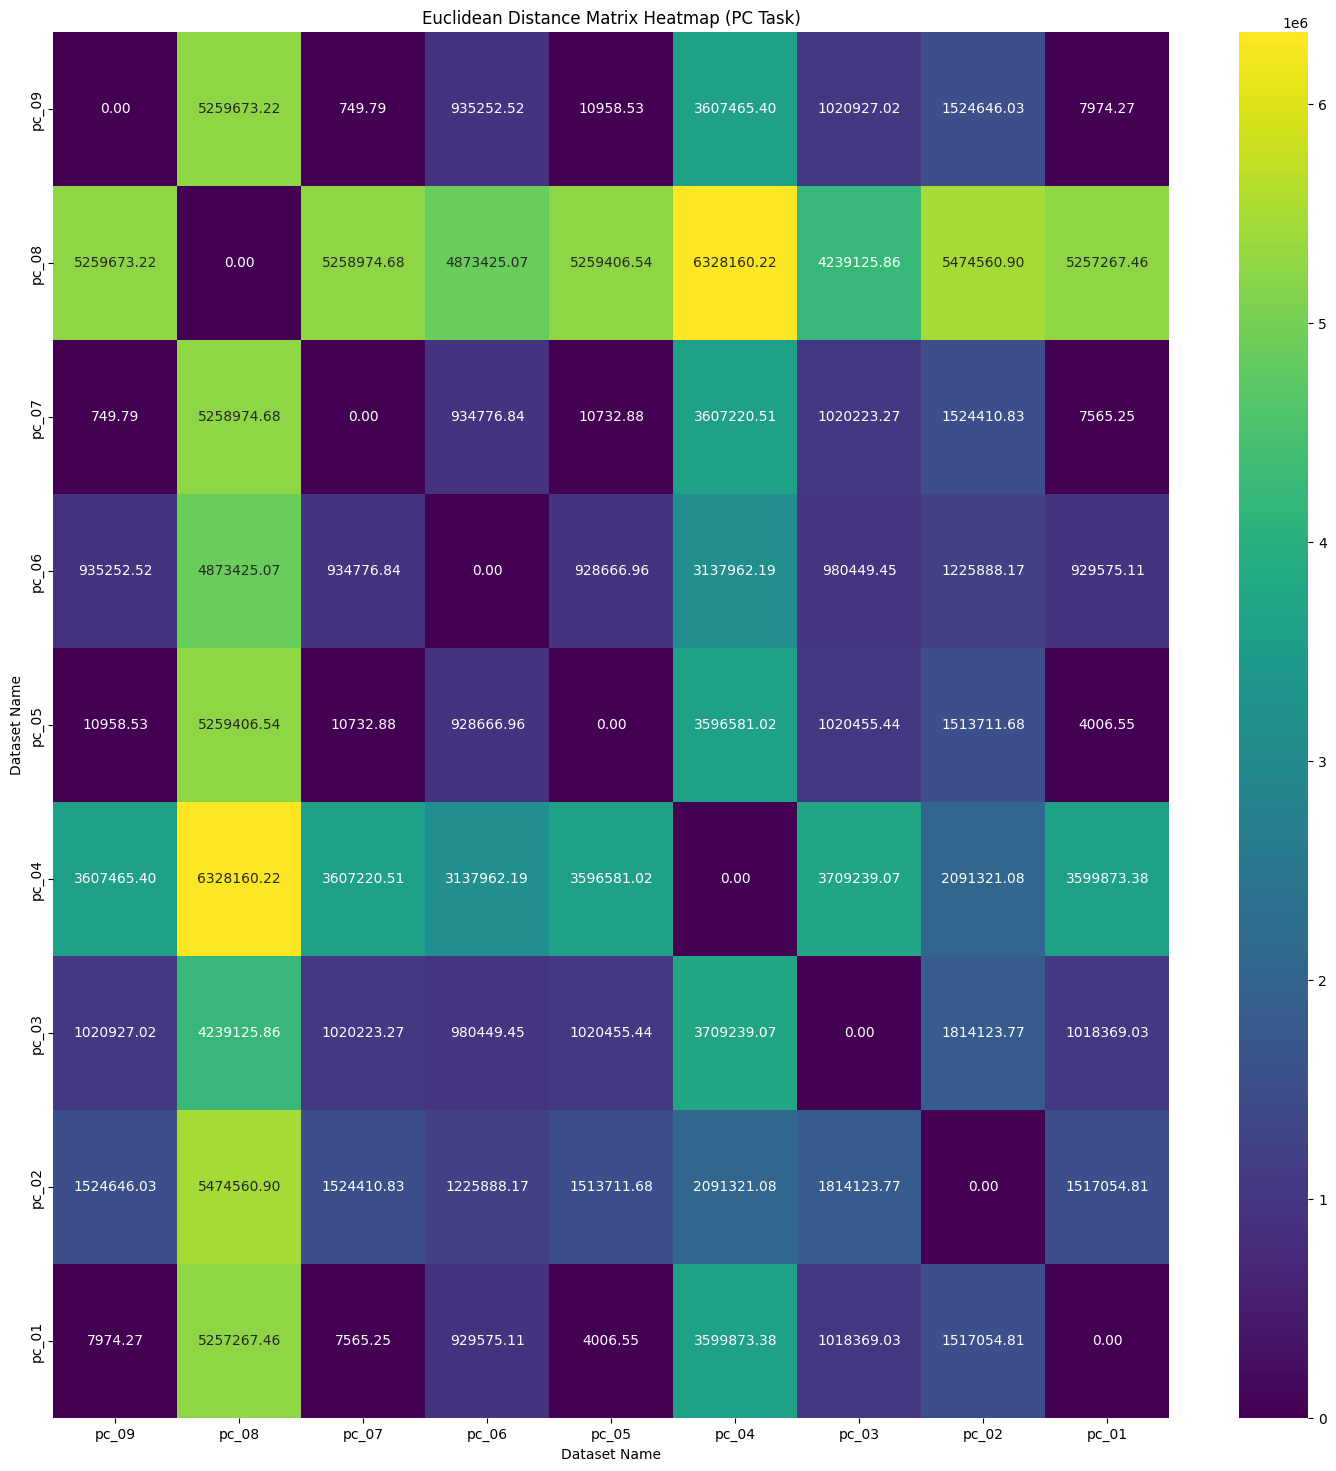

In [ ]:
pc_numeric_df = pc_df.drop(columns=["dataset_name"])
pc_numeric_df = pc_numeric_df.dropna()
pc_distance_matrix = pairwise_distances(pc_numeric_df, metric='euclidean')
pc_distance_matrix_df = pd.DataFrame(pc_distance_matrix, index=pc_df["dataset_name"], columns=pc_df["dataset_name"])

display(pc_distance_matrix)
display(pc_numeric_df)

plt.figure(figsize=(18, 18))
sns.heatmap(pc_distance_matrix_df, annot=True, fmt=".2f", cmap="viridis")
plt.title("Euclidean Distance Matrix Heatmap (PC Task)")
plt.xlabel("Dataset Name")
plt.ylabel("Dataset Name")
plt.show()

## sd

array([[0.00000000e+00, 4.94058130e+02, 1.95042233e+07, 1.23337554e+07],
       [4.94058130e+02, 0.00000000e+00, 1.95046346e+07, 1.23341668e+07],
       [1.95042233e+07, 1.95046346e+07, 0.00000000e+00, 7.17756245e+06],
       [1.23337554e+07, 1.23341668e+07, 7.17756245e+06, 0.00000000e+00]])

,number_labels,class_imbalance,entropy_vocabulary_distribution,entropy_words_per_document,vocabulary,vocabulary_document_ratio,ratio_mean_std_dev_tokens,ratio_mean_std_dev_unique_tokens,pca_noise_variance,minimum_number_tokens_per_document,...,average_pca_explained_variance,standard_deviation_pca_explained_variance,skewness_pca_explained_variance,kurtosis_pca_explained_variance,minimum_pca_explained_variance_ratio,maximum_pca_explained_variance_ratio,average_pca_explained_variance_ratio,standard_deviation_pca_explained_variance_ratio,skewness_pca_explained_variance_ratio,kurtosis_pca_explained_variance_ratio
6,3.0,1.427984,6.657086,6.629168,875.0,68.000000,1.884158,2.104591,0.0,1.0,...,253.901086,1.216171e+03,5.351107,28.971355,1.592367e-06,0.872084,0.033333,0.159665,5.351107,28.971355
7,3.0,1.240602,6.672803,6.647840,875.0,32.000000,2.028728,2.276415,0.0,2.0,...,244.702949,1.145515e+03,5.289911,28.447378,1.347655e-06,0.849677,0.033333,0.156042,5.289911,28.447378
8,5.0,4.070286,12.651070,12.502195,398237.0,7876.000000,0.881511,1.269785,0.0,1.0,...,640117.438815,3.501498e+06,5.477222,29.999973,6.889622e-11,0.998740,0.033333,0.182336,5.477222,29.999973
9,2.0,1.551136,5.896811,5.749905,449.0,71.142857,0.991453,1.435320,0.0,23.0,...,404964.526433,2.215133e+06,5.477222,29.999973,3.238468e-10,0.998714,0.033333,0.182331,5.477222,29.999973


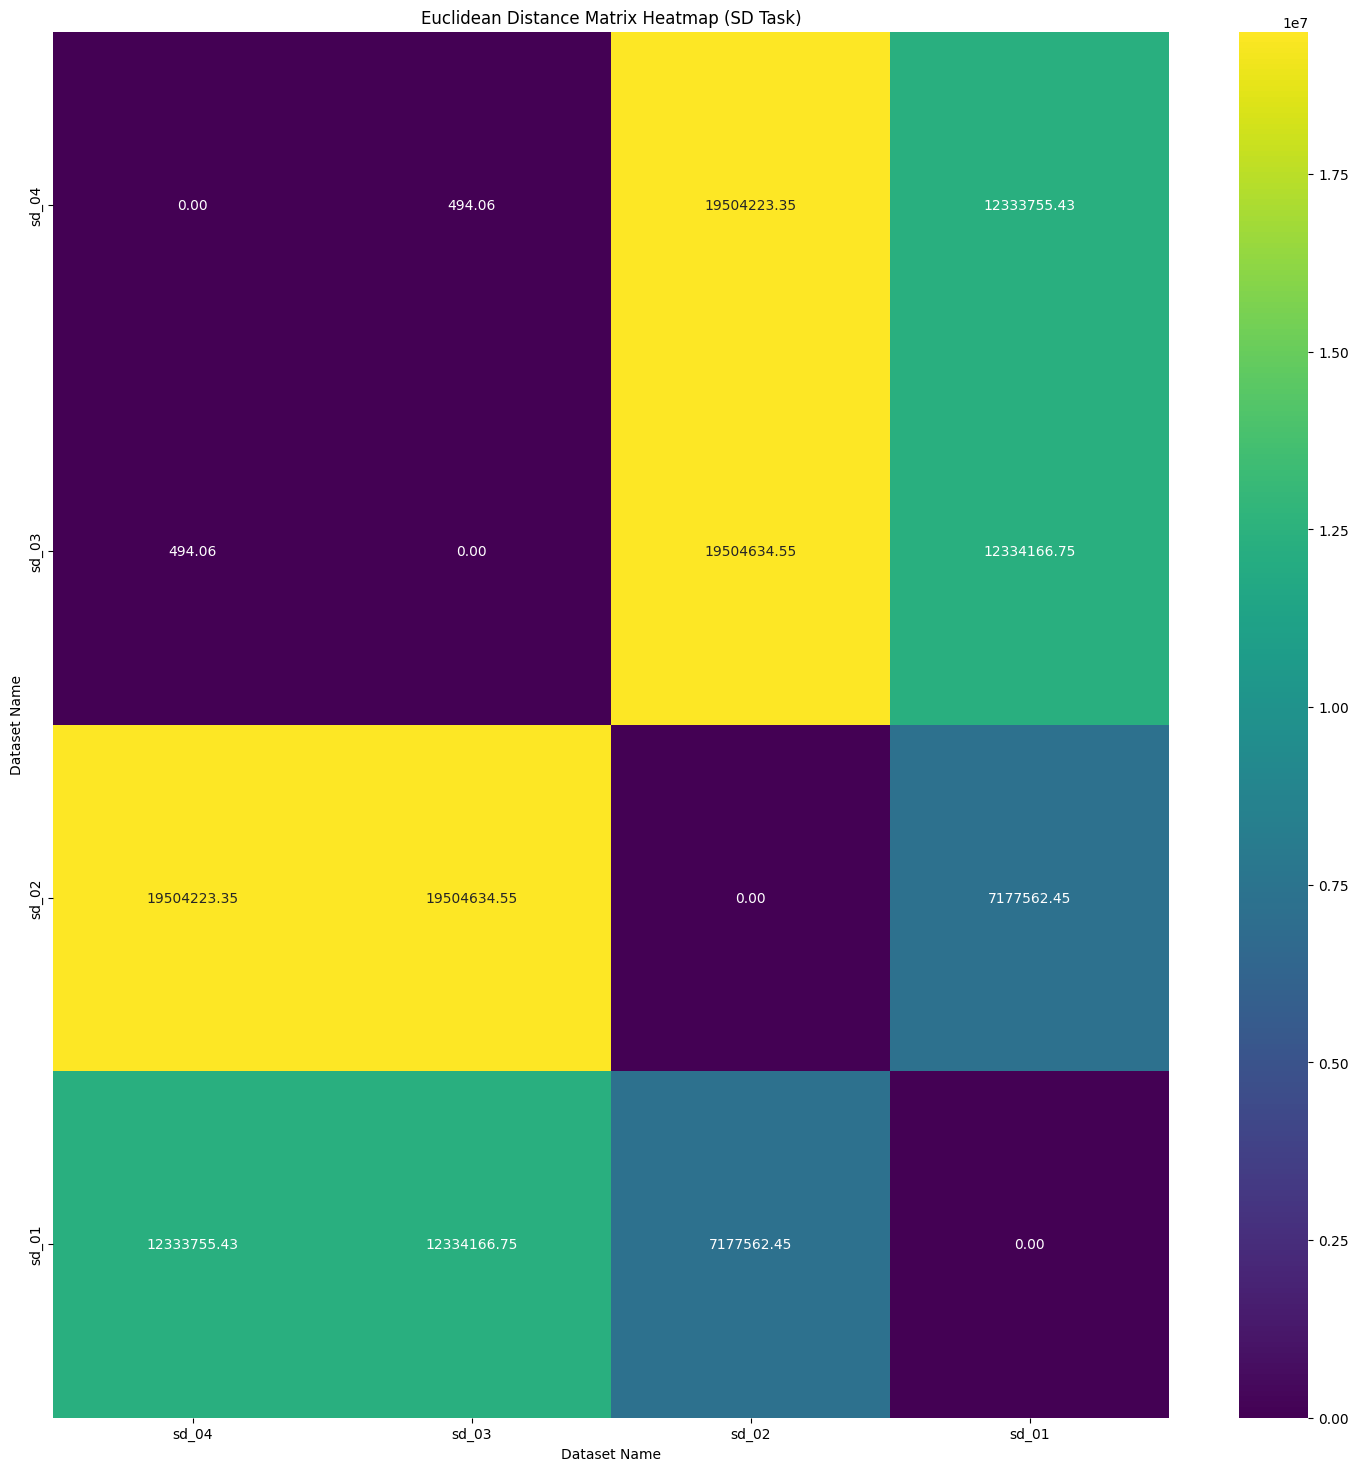

In [ ]:
sd_numeric_df = sd_df.drop(columns=["dataset_name"])
sd_numeric_df = sd_numeric_df.dropna()
sd_distance_matrix = pairwise_distances(sd_numeric_df, metric='euclidean')
sd_distance_matrix_df = pd.DataFrame(sd_distance_matrix, index=sd_df["dataset_name"], columns=sd_df["dataset_name"])

display(sd_distance_matrix)
display(sd_numeric_df)

plt.figure(figsize=(18, 18))
sns.heatmap(sd_distance_matrix_df, annot=True, fmt=".2f", cmap="viridis")
plt.title("Euclidean Distance Matrix Heatmap (SD Task)")
plt.xlabel("Dataset Name")
plt.ylabel("Dataset Name")
plt.show()

## ua

array([[     0.        , 335168.53808968, 457577.76439105,
         39793.10986788, 371446.66515815, 460536.72235231],
       [335168.53808968,      0.        , 215378.03608778,
        296301.13698465,  36444.74019223, 177126.97691144],
       [457577.76439105, 215378.03608778,      0.        ,
        425707.86734654, 201995.81145966,  63656.05507626],
       [ 39793.10986788, 296301.13698465, 425707.86734654,
             0.        , 332639.20525953, 425798.24713237],
       [371446.66515815,  36444.74019223, 201995.81145966,
        332639.20525953,      0.        , 155799.16306749],
       [460536.72235231, 177126.97691144,  63656.05507626,
        425798.24713237, 155799.16306749,      0.        ]])

,number_labels,class_imbalance,entropy_vocabulary_distribution,entropy_words_per_document,vocabulary,vocabulary_document_ratio,ratio_mean_std_dev_tokens,ratio_mean_std_dev_unique_tokens,pca_noise_variance,minimum_number_tokens_per_document,...,average_pca_explained_variance,standard_deviation_pca_explained_variance,skewness_pca_explained_variance,kurtosis_pca_explained_variance,minimum_pca_explained_variance_ratio,maximum_pca_explained_variance_ratio,average_pca_explained_variance_ratio,standard_deviation_pca_explained_variance_ratio,skewness_pca_explained_variance_ratio,kurtosis_pca_explained_variance_ratio
0,5.0,6.393542,9.335635,9.259538,14343.0,167.428571,1.022916,1.262385,0.0,8.0,...,14993.478474,81407.775084,5.476789,29.996689,3.446450e-10,0.991561,0.033333,0.180985,5.476789,29.996689
1,5.0,23.833333,6.546110,6.392680,937.0,299.000000,0.850790,1.155693,0.0,1.0,...,3912.369772,21320.244850,5.477176,29.999628,0.000000e+00,0.995094,0.033333,0.181648,5.477176,29.999628
2,5.0,1.003568,11.949349,11.848534,199422.0,213.000000,1.008527,1.280241,0.0,2.0,...,1166.516069,6316.475420,5.476690,29.995935,1.966153e-07,0.988957,0.033333,0.180494,5.476690,29.995935
3,5.0,35.115108,8.595951,8.413563,7176.0,415.500000,0.787439,1.125014,0.0,2.0,...,13625.087664,74495.043856,5.477220,29.999956,8.625121e-18,0.998282,0.033333,0.182250,5.477220,29.999956
4,10.0,7.158416,7.762931,7.649876,3030.0,355.000000,0.998308,1.304117,0.0,1.0,...,2723.926245,14789.126423,5.476935,29.997796,0.000000e+00,0.991533,0.033333,0.180978,5.476935,29.997796
5,5.0,9.875441,11.471933,11.386489,141202.0,224.000000,0.861291,1.002520,0.0,1.0,...,403.287063,1971.340360,5.380087,29.214681,1.785258e-06,0.890903,0.033333,0.162939,5.380087,29.214681


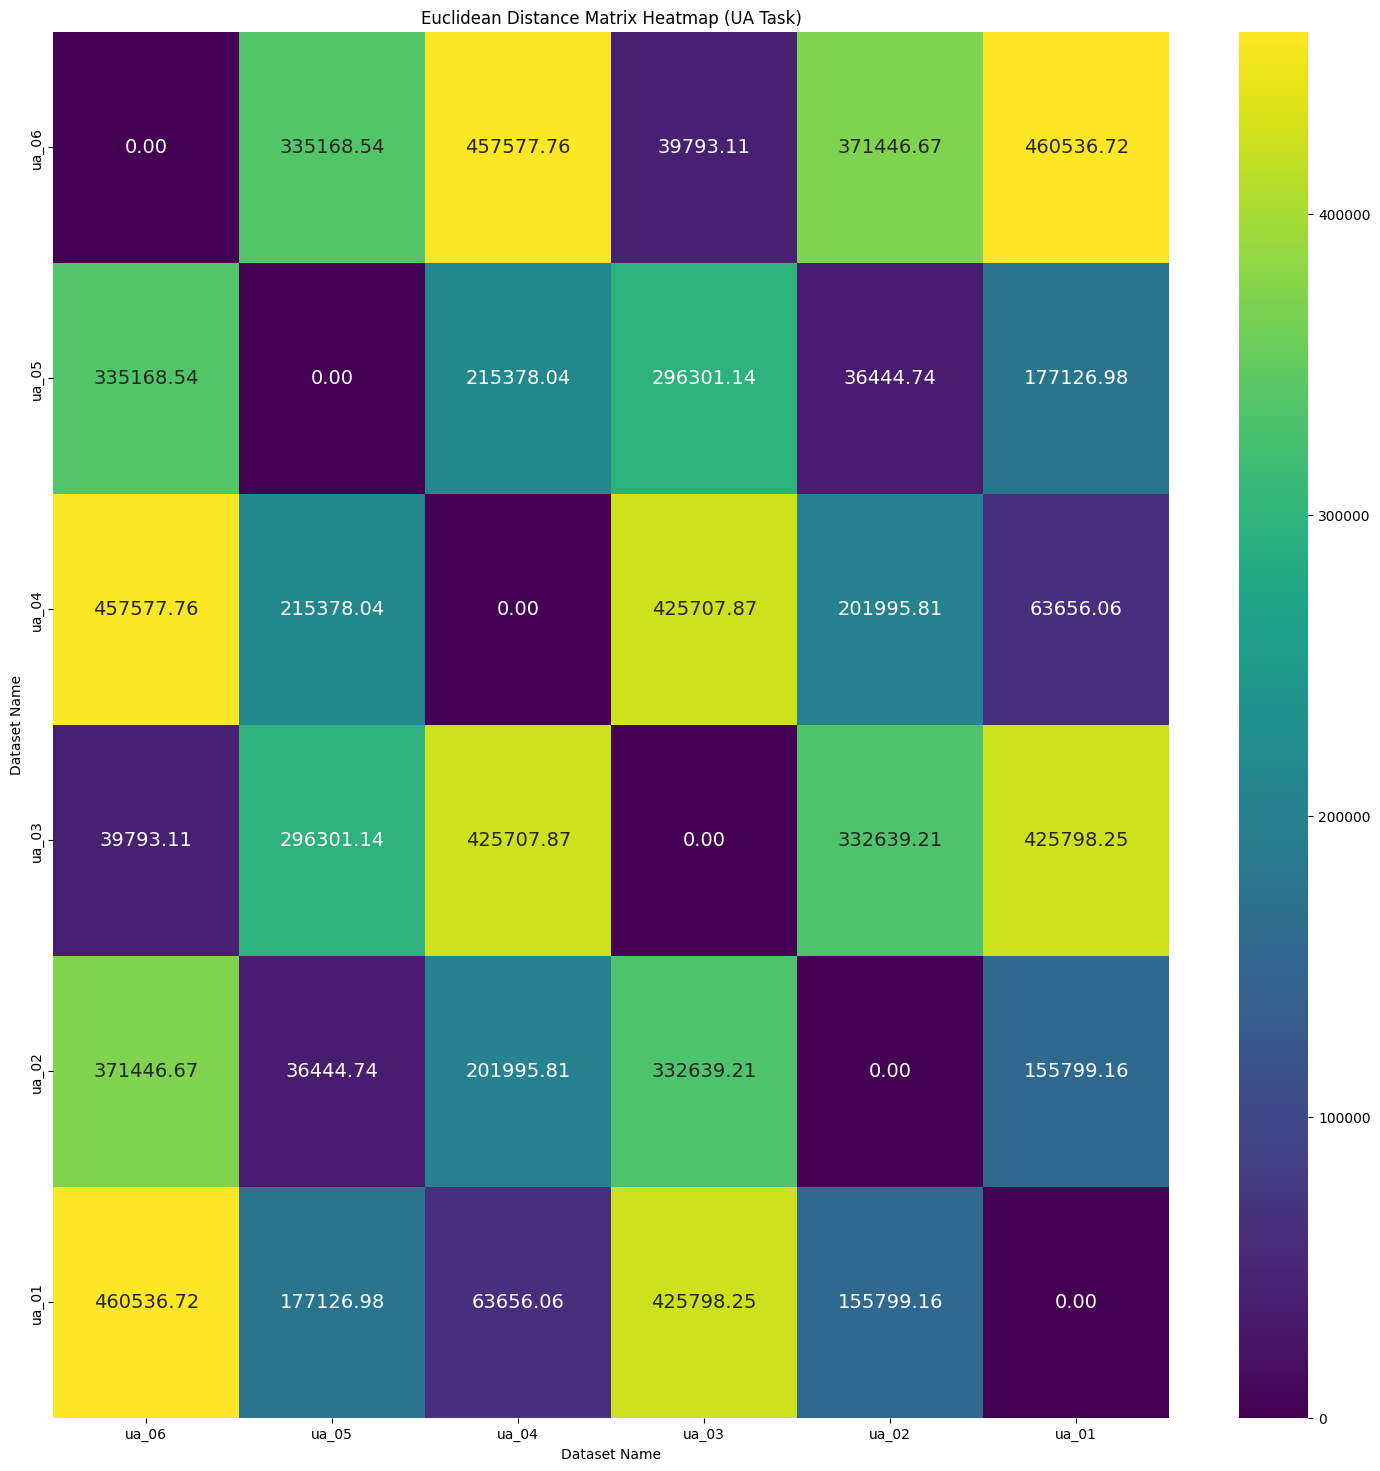

In [ ]:
ua_numeric_df = ua_df.drop(columns=["dataset_name"])
ua_numeric_df = ua_numeric_df.dropna()
ua_distance_matrix = pairwise_distances(ua_numeric_df, metric='euclidean')
ua_distance_matrix_df = pd.DataFrame(ua_distance_matrix, index=ua_df["dataset_name"], columns=ua_df["dataset_name"])

display(ua_distance_matrix)
display(ua_numeric_df)

plt.figure(figsize=(18, 18))
sns.heatmap(ua_distance_matrix_df, annot=True, fmt=".2f", cmap="viridis", annot_kws={"size": 14})
plt.title("Euclidean Distance Matrix Heatmap (UA Task)")
plt.xlabel("Dataset Name")
plt.ylabel("Dataset Name")
plt.savefig("ua_heatmap.pdf")
plt.show()

# Overall Performance

In [ ]:
df = pd.read_csv(f"/content/drive/MyDrive/Colab Notebooks/output/statistics/concat_rf.csv", sep=";")
df["task"] = df["trained_dataset"].apply(lambda x: x[:2])
adapt_mask = df["concatenated_dataset"] == df["predicted_dataset"]
aug_mask = df["trained_dataset"] == df["predicted_dataset"]

not_aug_df = df.loc[(~aug_mask)]
not_aug_df

,trained_dataset,predicted_dataset,concatenated_dataset,automl_system,method,percentage,missing_in_pred,extra_in_pred,only_one_predicted_label,f1_micro_majority,hold_out_f1_score,y_true_labels,y_pred_labels,task
0,ed_03,ed_01,ed_01,Random Forest with Random Search,gmm_random,25,"['disgust', 'sadness', 'joy', 'surprise', 'fea...",['neutral'],True,0.307054,0.000000,"['disgust', 'sadness', 'joy', 'surprise', 'fea...",['neutral'],ed
1,ed_03,ed_02,ed_01,Random Forest with Random Search,gmm_random,25,"['sadness', 'joy', 'surprise', 'fear', 'anger'...",['neutral'],True,0.342871,0.000000,"['sadness', 'joy', 'surprise', 'fear', 'anger'...",['neutral'],ed
3,ed_03,ed_01,ed_01,Random Forest with Random Search,gmm_random,50,"['disgust', 'sadness', 'joy', 'surprise', 'fea...",['neutral'],True,0.307054,0.000000,"['disgust', 'sadness', 'joy', 'surprise', 'fea...",['neutral'],ed
4,ed_03,ed_02,ed_01,Random Forest with Random Search,gmm_random,50,"['sadness', 'joy', 'surprise', 'fear', 'anger'...",['neutral'],True,0.342871,0.000000,"['sadness', 'joy', 'surprise', 'fear', 'anger'...",['neutral'],ed
6,ed_03,ed_01,ed_01,Random Forest with Random Search,gmm_random,75,"['disgust', 'sadness', 'joy', 'surprise', 'fea...",['neutral'],True,0.307054,0.000000,"['disgust', 'sadness', 'joy', 'surprise', 'fea...",['neutral'],ed
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2033,ua_06,ua_05,ua_05,Random Forest with Random Search,gmm_random,50,"['1', '5', '3', '7']",[],True,0.776119,0.776119,"['10', '7', '5', '1', '3']",['10'],ua
2035,ua_06,ua_01,ua_05,Random Forest with Random Search,gmm_random,75,"['1', '5', '3', '7']",[],True,0.558380,0.558380,"['10', '7', '5', '1', '3']",['10'],ua
2036,ua_06,ua_03,ua_05,Random Forest with Random Search,gmm_random,75,"['1', '5', '3', '7']",[],True,0.666016,0.666016,"['10', '7', '5', '1', '3']",['10'],ua
2037,ua_06,ua_04,ua_05,Random Forest with Random Search,gmm_random,75,"['1', '5', '3', '7']",[],True,0.200040,0.200040,"['10', '7', '5', '1', '3']",['10'],ua


In [ ]:
hpo = pd.read_csv(
    "/content/drive/MyDrive/Colab Notebooks/output/statistics/hpo_all_systems.csv",
    sep=";"
)
system_map = {
    "rf": "Random Forest with Random Search",
    "ag": "AutoGluon",
    "flaml": "FLAML",
}

hpo = hpo[hpo["automl_system"] == system_map["rf"]]
hpo["are_concat_pred_equal"] = hpo.apply(
    lambda row: row["trained_dataset"] == row["predicted_dataset"],
    axis=1
)
hpo

,trained_dataset,predicted_dataset,automl_system,method,percentage,missing_in_pred,extra_in_pred,only_one_predicted_label,f1_micro_majority,hold_out_f1_score,y_true_labels,y_pred_labels,are_concat_pred_equal
347,sd_01,sd_01,Random Forest with Random Search,gmm_random,100,[],[],False,0.687500,0.807292,"['hyperpartisan', 'not_hyperpartisan']","['hyperpartisan', 'not_hyperpartisan']",True
348,fn_03,fn_02,Random Forest with Random Search,gmm_random,100,"['false', 'true']",['half_true'],True,0.520833,0.000000,"['false', 'true']",['half_true'],False
349,fn_03,fn_06,Random Forest with Random Search,gmm_random,100,"['false', 'true']",['half_true'],True,0.535865,0.000000,"['false', 'true']",['half_true'],False
350,fn_03,fn_03,Random Forest with Random Search,gmm_random,100,"['pants_on_fire', 'mostly_false', 'full_flop',...",[],True,0.198683,0.198683,"['pants_on_fire', 'mostly_false', 'full_flop',...",['half_true'],True
351,fn_09,fn_10,Random Forest with Random Search,gmm_random,100,"['false', 'true', 'no_opinion']",[],True,0.516667,0.108333,"['out_of_scope', 'false', 'true', 'no_opinion']",['out_of_scope'],False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
517,pc_08,pc_06,Random Forest with Random Search,gmm_random,100,['negative'],[],True,0.500622,0.499378,"['negative', 'positive']",['positive'],False
518,pc_08,pc_07,Random Forest with Random Search,gmm_random,100,"['negative', 'neutral']",[],True,0.502058,0.078189,"['positive', 'negative', 'neutral']",['positive'],False
519,pc_08,pc_08,Random Forest with Random Search,gmm_random,100,"['neutral', 'negative']",[],True,0.479628,0.479628,"['neutral', 'negative', 'positive']",['positive'],True
520,hs_02,hs_13,Random Forest with Random Search,gmm_random,100,"['neither', 'hate']",[],True,0.816537,0.126615,"['hate', 'offensive', 'neither']",['offensive'],False


In [ ]:
df = pd.read_csv(f"/content/drive/MyDrive/Colab Notebooks/output/statistics/concat_ag.csv", sep=";")
df["task"] = df["trained_dataset"].apply(lambda x: x[:2])
adapt_mask = df["concatenated_dataset"] == df["predicted_dataset"]
aug_mask = df["trained_dataset"] == df["predicted_dataset"]


not_aug_df = df.loc[(~aug_mask)]
not_aug_df

,trained_dataset,predicted_dataset,concatenated_dataset,automl_system,method,percentage,missing_in_pred,extra_in_pred,only_one_predicted_label,f1_micro_majority,hold_out_f1_score,y_true_labels,y_pred_labels,task
0,ed_03,ed_01,ed_01,AutoGluon,gmm_random,25,"['surprise', 'disgust', 'anger']","['admiration', 'disappointment', 'neutral', 'g...",False,0.307054,0.132780,"['sadness', 'joy', 'surprise', 'fear', 'anger'...","['admiration', 'sadness', 'joy', 'disappointme...",ed
1,ed_03,ed_02,ed_01,AutoGluon,gmm_random,25,[],"['curiosity', 'nervousness', 'embarrassment', ...",False,0.342871,0.107823,"['sadness', 'joy', 'surprise', 'fear', 'love',...","['sadness', 'embarrassment', 'excitement', 'an...",ed
3,ed_03,ed_01,ed_01,AutoGluon,gmm_random,50,['anger'],"['curiosity', 'admiration', 'remorse', 'neutral']",False,0.307054,0.302905,"['sadness', 'joy', 'surprise', 'fear', 'anger'...","['curiosity', 'admiration', 'sadness', 'joy', ...",ed
4,ed_03,ed_02,ed_01,AutoGluon,gmm_random,50,[],"['curiosity', 'nervousness', 'embarrassment', ...",False,0.342871,0.147415,"['sadness', 'joy', 'surprise', 'fear', 'love',...","['sadness', 'embarrassment', 'excitement', 'an...",ed
6,ed_03,ed_01,ed_01,AutoGluon,gmm_random,75,[],"['neutral', 'admiration', 'remorse']",False,0.307054,0.294606,"['sadness', 'joy', 'surprise', 'fear', 'anger'...","['admiration', 'sadness', 'joy', 'surprise', '...",ed
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2033,ua_06,ua_05,ua_05,AutoGluon,gmm_random,50,"['3', '7']",[],False,0.776119,0.796020,"['3', '5', '10', '1', '7']","['5', '10', '1']",ua
2035,ua_06,ua_01,ua_05,AutoGluon,gmm_random,75,[],[],False,0.558380,0.577014,"['3', '5', '10', '1', '7']","['3', '5', '10', '1', '7']",ua
2036,ua_06,ua_03,ua_05,AutoGluon,gmm_random,75,['5'],[],False,0.666016,0.667317,"['3', '5', '10', '1', '7']","['3', '7', '10', '1']",ua
2037,ua_06,ua_04,ua_05,AutoGluon,gmm_random,75,[],[],False,0.200040,0.261252,"['3', '5', '10', '1', '7']","['3', '5', '10', '1', '7']",ua


In [ ]:
hpo = pd.read_csv(
    "/content/drive/MyDrive/Colab Notebooks/output/statistics/hpo_all_systems.csv",
    sep=";"
)
system_map = {
    "rf": "Random Forest with Random Search",
    "ag": "AutoGluon",
    "flaml": "FLAML",
}

hpo = hpo[hpo["automl_system"] == system_map["ag"]]
hpo["are_concat_pred_equal"] = hpo.apply(
    lambda row: row["trained_dataset"] == row["predicted_dataset"],
    axis=1
)
hpo.head()

,trained_dataset,predicted_dataset,automl_system,method,percentage,missing_in_pred,extra_in_pred,only_one_predicted_label,f1_micro_majority,hold_out_f1_score,y_true_labels,y_pred_labels,are_concat_pred_equal
143,fn_02,fn_06,AutoGluon,gmm_random,100,[],[],False,0.535865,0.502110,"['false', 'true']","['false', 'true']",False
144,fn_02,fn_02,AutoGluon,gmm_random,100,[],[],False,0.520833,0.500000,"['false', 'true']","['false', 'true']",True
145,hs_09,hs_03,AutoGluon,gmm_random,100,['hate'],[],True,0.502101,0.497899,"['not_hate', 'hate']",['not_hate'],False
146,hs_09,hs_06,AutoGluon,gmm_random,100,['hate'],[],True,0.577408,0.577408,"['not_hate', 'hate']",['not_hate'],False
147,hs_09,hs_08,AutoGluon,gmm_random,100,['hate'],[],True,0.930996,0.930996,"['not_hate', 'hate']",['not_hate'],False


In [ ]:
df = pd.read_csv(f"/content/drive/MyDrive/Colab Notebooks/output/statistics/concat_flaml.csv", sep=";")
df["task"] = df["trained_dataset"].apply(lambda x: x[:2])
adapt_mask = df["concatenated_dataset"] == df["predicted_dataset"]
aug_mask = df["trained_dataset"] == df["predicted_dataset"]


not_aug_df = df.loc[(~aug_mask)]
not_aug_df

,trained_dataset,predicted_dataset,concatenated_dataset,automl_system,method,percentage,missing_in_pred,extra_in_pred,only_one_predicted_label,f1_micro_majority,hold_out_f1_score,y_true_labels,y_pred_labels,task
1,hs_04,hs_14,hs_14,FLAML,gmm_random,25,[],[],False,0.517544,0.600877,"['toxic', 'not_toxic']","['toxic', 'not_toxic']",hs
3,hs_04,hs_14,hs_14,FLAML,gmm_random,50,[],[],False,0.517544,0.605263,"['toxic', 'not_toxic']","['toxic', 'not_toxic']",hs
5,hs_04,hs_14,hs_14,FLAML,gmm_random,75,[],[],False,0.517544,0.894737,"['toxic', 'not_toxic']","['toxic', 'not_toxic']",hs
6,fn_05,fn_07,fn_07,FLAML,gmm_random,25,[],[],False,0.369318,0.406250,"['refutation', 'support', 'insufficient_info']","['support', 'insufficient_info', 'refutation']",fn
8,fn_05,fn_07,fn_07,FLAML,gmm_random,50,[],[],False,0.369318,0.409091,"['refutation', 'support', 'insufficient_info']","['support', 'refutation', 'insufficient_info']",fn
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2034,pc_04,pc_06,pc_06,FLAML,gmm_random,50,[],[],False,0.500622,0.889010,"['negative', 'positive']","['negative', 'positive']",pc
2035,pc_04,pc_01,pc_06,FLAML,gmm_random,75,[],[],False,0.501181,0.775154,"['negative', 'positive']","['negative', 'positive']",pc
2036,pc_04,pc_02,pc_06,FLAML,gmm_random,75,[],[],False,0.501416,0.798867,"['negative', 'positive']","['negative', 'positive']",pc
2037,pc_04,pc_03,pc_06,FLAML,gmm_random,75,[],[],False,0.501573,0.831653,"['negative', 'positive']","['negative', 'positive']",pc


In [ ]:
hpo = pd.read_csv(
    "/content/drive/MyDrive/Colab Notebooks/output/statistics/hpo_all_systems.csv",
    sep=";"
)
system_map = {
    "rf": "Random Forest with Random Search",
    "ag": "AutoGluon",
    "flaml": "FLAML",
}

hpo = hpo[hpo["automl_system"] == system_map["flaml"]]
hpo["are_concat_pred_equal"] = hpo.apply(
    lambda row: row["trained_dataset"] == row["predicted_dataset"],
    axis=1
)
hpo.head()

,trained_dataset,predicted_dataset,automl_system,method,percentage,missing_in_pred,extra_in_pred,only_one_predicted_label,f1_micro_majority,hold_out_f1_score,y_true_labels,y_pred_labels,are_concat_pred_equal
0,pc_02,pc_01,FLAML,gmm_random,100,[],[],False,0.501181,0.706188,"['negative', 'positive']","['negative', 'positive']",False
1,pc_02,pc_03,FLAML,gmm_random,100,[],[],False,0.501573,0.731290,"['negative', 'positive']","['negative', 'positive']",False
2,pc_02,pc_04,FLAML,gmm_random,100,[],[],False,0.500481,0.777217,"['negative', 'positive']","['negative', 'positive']",False
3,pc_02,pc_06,FLAML,gmm_random,100,[],[],False,0.500622,0.825439,"['negative', 'positive']","['negative', 'positive']",False
4,pc_02,pc_02,FLAML,gmm_random,100,[],[],False,0.501416,0.796034,"['negative', 'positive']","['negative', 'positive']",True
